### Group 5: Obama NLP Analysis
A text analysis of Barack Obama’s official presidential speeches from 2009–2016, using the Obama corpus from Lund University Humanities Lab Archive.

In [5]:
#import all the things

import json
from pathlib import Path
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns


## Dataset

In [6]:
#load dataset

data_dir = Path.cwd() / 'data'
file_path = data_dir / 'Obama_Speeches.json'

if not file_path.is_file():
    raise FileNotFoundError(
        f'Missing dataset: {file_path}. See the README for setup instructions.')

with file_path.open('r', encoding='utf-8') as file:
    data = json.load(file)


#convert to csv    

df = pd.DataFrame(data)
df.to_csv(data_dir / 'Obama_Speeches.csv', index=False, encoding='utf-8')

In [ ]:
#preview original dataset

df.head(5)

,transcript,title,date,link,word_count,character_count,avg_word_len,stop_word_count,stop_word_rate,non_stopwords,lemmatized,polarity,subjectivity
0,thank you very much. please. thank you. the fi...,abraham-accords-signing-ceremony-transcript-se...,"Sep 15, 2020",https://www.rev.com/transcript-editor/shared/c...,955,4447,4.656545,437,0.457592,thank much please thank first lady honored wel...,thank much please thank first lady honored wel...,0.238266,0.458421
1,"yeah. around that time, yes. maybe a year late...",all-released-portions-of-trumps-10-19-22-depos...,"May 8, 2023",https://www.rev.com/transcript-editor/shared/y...,2977,11520,3.869667,1585,0.532415,yeah around time yes maybe year later thats ri...,yeah around time yes maybe year later thats ri...,0.077526,0.518494
2,thank you very much. appreciate it. thank you ...,amy-coney-barrett-swearing-in-ceremony-transcript,"Oct 26, 2020",https://www.rev.com/transcript-editor/shared/q...,981,4645,4.734964,452,0.460754,thank much appreciate thank much distinguished...,thank much appreciate thank much distinguished...,0.325494,0.526735
3,thank you. . nice to see you. thank you. thank...,cnn-donald-trump-town-hall-5-10-23-transcript,"May 11, 2023",https://www.rev.com/transcript-editor/shared/I...,8392,34149,4.069233,4510,0.537417,thank nice see thank thank thank fantastically...,thank nice see thank thank thank fantastically...,0.102392,0.539212
4,thank you very much everyone. thank you. progr...,coronavirus-task-force-briefing-transcript-mar...,"Mar 17, 2020",https://www.rev.com/transcript-editor/shared/d...,6519,27277,4.184231,3379,0.518331,thank much everyone thank progress made apprec...,thank much everyone thank progress made apprec...,0.186451,0.536127


avg_word_len = average length of words in characters. higher value means he used longer words.

stop_word_rate = stop_word_count / word_count, gives what percentage of the speech are stop words.

non_stopwords = the speech without stopwords

lemmatized = the words of speech transformed into their stem forms

polarity = sentiment-analysis value, negative towards –1, neutral closer to 0, positive closer to +1.

subjectivity = value between 0 to 1 regarding how subjective the speech is, 0 more objective, 1 more subjective.

In [54]:
#sort original dataset by date

df['date'] = pd.to_datetime(df['date'])
df = (df.sort_values('date').reset_index(drop=True))

df.head(5)

,transcript,title,date,link,word_count,character_count,avg_word_len,stop_word_count,stop_word_rate,non_stopwords,lemmatized,polarity,subjectivity
0,excuse me. okay. let’s. you got to let me spea...,donald-trump-says-i-like-people-who-werent-cap...,2015-07-20,https://www.rev.com/transcript-editor/shared/6...,1045,4254,4.070813,514,0.491866,excuse okay lets got let speak though frank in...,excuse okay let got let speak though frank int...,0.053938,0.562462
1,thank you very much. thank you. thank you. wha...,donald-trump-michigan-speech-transcript-asks-b...,2016-04-19,https://www.rev.com/transcript-editor/shared/a...,4151,18278,4.403276,2056,0.495302,thank much thank thank crowd wow look boy crow...,thank much thank thank crowd wow look boy crow...,0.121177,0.404294
2,thank you. lester. our jobs are fleeing the co...,donald-trump-vs-hillary-clinton-1st-presidenti...,2016-09-26,https://www.rev.com/transcript-editor/shared/U...,8438,35066,4.155724,4499,0.533183,thank lester jobs fleeing country theyre going...,thank lester job fleeing country theyre going ...,0.123893,0.528972
3,"well, i actually agree with that. i agree with...",donald-trump-vs-hillary-clinton-2nd-presidenti...,2016-10-09,https://www.rev.com/transcript-editor/shared/C...,6731,28465,4.228941,3537,0.525479,well actually agree agree everything said bega...,well actually agree agree everything said bega...,0.097899,0.531789
4,"well, first of all, it’s great to be with you ...",donald-trump-vs-hillary-clinton-3rd-presidenti...,2016-10-19,https://www.rev.com/transcript-editor/shared/p...,6497,26830,4.129598,3464,0.533169,well first great thank everybody supreme court...,well first great thank everybody supreme court...,0.060618,0.512726


In [ ]:
#only the original transcript, title and date

obama_speeches = df[['transcript', 'title', 'date']].copy()
obama_speeches.head()

,transcript,title,date
0,thank you very much. please. thank you. the fi...,abraham-accords-signing-ceremony-transcript-se...,"Sep 15, 2020"
1,"yeah. around that time, yes. maybe a year late...",all-released-portions-of-trumps-10-19-22-depos...,"May 8, 2023"
2,thank you very much. appreciate it. thank you ...,amy-coney-barrett-swearing-in-ceremony-transcript,"Oct 26, 2020"
3,thank you. . nice to see you. thank you. thank...,cnn-donald-trump-town-hall-5-10-23-transcript,"May 11, 2023"
4,thank you very much everyone. thank you. progr...,coronavirus-task-force-briefing-transcript-mar...,"Mar 17, 2020"


In [ ]:
#sort the entries after date

obama_speeches['date'] = pd.to_datetime(obama_speeches['date'])
obama_speeches = (obama_speeches.sort_values('date').reset_index(drop=True))


#change the order of the columns

obama_speeches = obama_speeches[['date', 'title', 'transcript']]

In [ ]:
#preview after sorting

obama_speeches.head()

,date,title,transcript
0,2015-07-20,donald-trump-says-i-like-people-who-werent-cap...,excuse me. okay. let’s. you got to let me spea...
1,2016-04-19,donald-trump-michigan-speech-transcript-asks-b...,thank you very much. thank you. thank you. wha...
2,2016-09-26,donald-trump-vs-hillary-clinton-1st-presidenti...,thank you. lester. our jobs are fleeing the co...
3,2016-10-09,donald-trump-vs-hillary-clinton-2nd-presidenti...,"well, i actually agree with that. i agree with..."
4,2016-10-19,donald-trump-vs-hillary-clinton-3rd-presidenti...,"well, first of all, it’s great to be with you ..."


## NLP Preprocessing

In [35]:
#import all the things

import nltk
nltk.download('punkt_tab') # Tokenizer
nltk.download('vader_lexicon') # Sentiment analysis
nltk.download('stopwords') # Stopwords
import gensim.downloader as api
from gensim import corpora
from gensim.models import LdaModel
from gensim.utils import simple_preprocess
wv = api.load("glove-wiki-gigaword-50")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/alexandrafrick/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/alexandrafrick/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/alexandrafrick/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [37]:
#tokenize

from nltk.tokenize import word_tokenize, sent_tokenize

sentences_0 = sent_tokenize(obama_speeches["transcript"].iloc[0])
words_0 = word_tokenize(obama_speeches["transcript"].iloc[0])

print(sentences_0)
print(words_0)

['excuse me.', 'okay.', 'let’s.', 'you got to let me speak though frank because you interrupt all the time, okay?', 'no, i know him too well, that’s the problem.', 'let’s take john mccain.', 'i’m in phoenix.', 'we have a meeting that is going to have 500 people at the biltmore hotel.', 'we get a call from the hotel, it’s turmoil.', 'thousands and thousands of people showing up three, four days before, they’re pitching tents on the hotel grass.', 'the hotel says, “we can’t handle this.', 'it’s going to destroy the hotel.”', 'we move it to the convention center.', 'we have 15,000 people, john, the biggest one ever bigger than bernie sanders, bigger than… 15,000 people showed up to hear me speak, bigger than anybody, and everybody knows it.', 'a beautiful day with incredible people that were wonderful great americans, i will tell you.', 'john mccain goes up, “oh boy, trump makes my life difficult.', 'he had 15,000 crazies show up.”', 'crazies, he called them all crazy.', 'i said, “they we

In [ ]:
#stopwords, removing stopwords and punctuation

from nltk.corpus import stopwords
stop_words = stopwords.words('english')
print(stop_words[:10])

preproc_sentences = []
for sentence in sentences_0: 
    sentence = simple_preprocess(sentence)
    sentence = [w for w in sentence if w.lower() not in stop_words] 
    preproc_sentences.append(sentence)
        
print(preproc_sentences)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']
[['excuse'], ['okay'], ['let'], ['got', 'let', 'speak', 'though', 'frank', 'interrupt', 'time', 'okay'], ['know', 'well', 'problem'], ['let', 'take', 'john', 'mccain'], ['phoenix'], ['meeting', 'going', 'people', 'biltmore', 'hotel'], ['get', 'call', 'hotel', 'turmoil'], ['thousands', 'thousands', 'people', 'showing', 'three', 'four', 'days', 'pitching', 'tents', 'hotel', 'grass'], ['hotel', 'says', 'handle'], ['going', 'destroy', 'hotel'], ['move', 'convention', 'center'], ['people', 'john', 'biggest', 'one', 'ever', 'bigger', 'bernie', 'sanders', 'bigger', 'people', 'showed', 'hear', 'speak', 'bigger', 'anybody', 'everybody', 'knows'], ['beautiful', 'day', 'incredible', 'people', 'wonderful', 'great', 'americans', 'tell'], ['john', 'mccain', 'goes', 'oh', 'boy', 'trump', 'makes', 'life', 'difficult'], ['crazies', 'show'], ['crazies', 'called', 'crazy'], ['said', 'crazy'], ['great', 'americans'], ['people',

In [ ]:
#ignoring to lemmatize for now, want to keep the speeches intact

## Sentiment analysis

In [ ]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

first_speech = df['transcript'].iloc[0]
print(sia.polarity_scores(first_speech))

In [71]:
first_speech = df["transcript"].iloc[0]
sentences = sent_tokenize(first_speech)

sia = SentimentIntensityAnalyzer()
sentiments = [sia.polarity_scores(sentence) for sentence in sentences]

print(sentences[:2])
print(sentiments[:2])


['excuse me.', 'okay.']
[{'neg': 0.0, 'neu': 0.435, 'pos': 0.565, 'compound': 0.0772}, {'neg': 0.0, 'neu': 0.0, 'pos': 1.0, 'compound': 0.2263}]


In [72]:
import numpy as np
sentiment_scores = [s['compound'] for s in sentiments]
# Which sentence were the most positive and negative?
print('Most positive: ' + sentences[np.argmax(sentiment_scores)])
print('Most negative: ' + sentences[np.argmin(sentiment_scores)])

Most positive: he was the greatest guy and then he passed away, but he was a great… he wrote the power of positive thinking, which is a great book.
Most negative: this country has great potential, but soon it’s not going to have that potential because we’re being drained by incompetent leaders, by horrible people.


Text(0.5, 0, 'Speech Index')

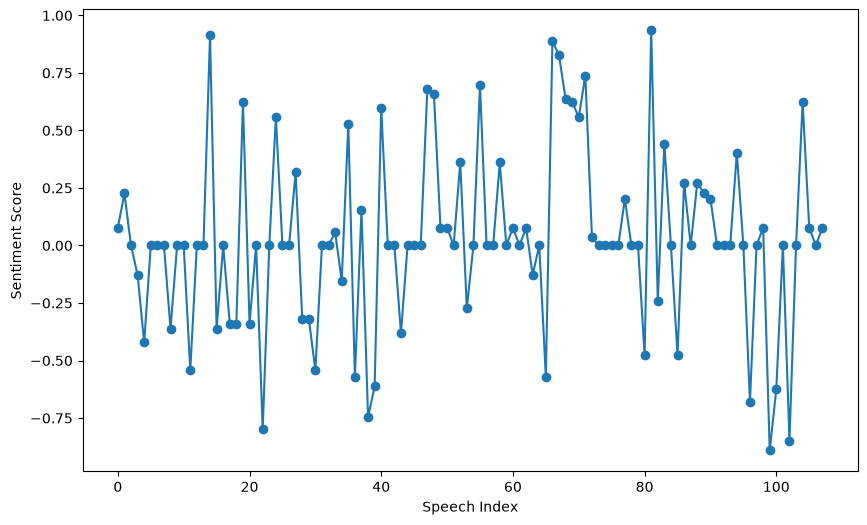

In [76]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, figsize=(10, 6))
ax.plot(sentiment_scores, marker='o')
ax.set_ylabel('Sentiment Score')
ax.set_xlabel('Speech Index')

## Topic Modelling

In [78]:
from gensim import corpora
from gensim.models import LdaModel
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
import numpy as np
import pandas as pd

In [81]:
lemmatizer = WordNetLemmatizer()
stop_words = stopwords.words('english') 
sentences = sent_tokenize(df['transcript'].iloc[0])
preproc_sentence = []
for sentence in sentences:
    sentence = simple_preprocess(sentence)
    sentence = [lemmatizer.lemmatize(w.lower()) for w in sentence if w.lower() not in stop_words]
    preproc_sentence.append(sentence)
print(preproc_sentence)

[['excuse'], ['okay'], ['let'], ['got', 'let', 'speak', 'though', 'frank', 'interrupt', 'time', 'okay'], ['know', 'well', 'problem'], ['let', 'take', 'john', 'mccain'], ['phoenix'], ['meeting', 'going', 'people', 'biltmore', 'hotel'], ['get', 'call', 'hotel', 'turmoil'], ['thousand', 'thousand', 'people', 'showing', 'three', 'four', 'day', 'pitching', 'tent', 'hotel', 'grass'], ['hotel', 'say', 'handle'], ['going', 'destroy', 'hotel'], ['move', 'convention', 'center'], ['people', 'john', 'biggest', 'one', 'ever', 'bigger', 'bernie', 'sander', 'bigger', 'people', 'showed', 'hear', 'speak', 'bigger', 'anybody', 'everybody', 'know'], ['beautiful', 'day', 'incredible', 'people', 'wonderful', 'great', 'american', 'tell'], ['john', 'mccain', 'go', 'oh', 'boy', 'trump', 'make', 'life', 'difficult'], ['crazy', 'show'], ['crazy', 'called', 'crazy'], ['said', 'crazy'], ['great', 'american'], ['people', 'would', 'seen', 'people', 'know', 'crazy'], ['know', 'crazy', 'crazy'], ['insulted', 'insulte

In [82]:
# Make dictionary
dictionary = corpora.Dictionary(preproc_sentence)
# Make counts of each word
corpus = [dictionary.doc2bow(t) for t in preproc_sentence]
lda = LdaModel(corpus, num_topics=4, id2word=dictionary, random_state=42)

In [83]:
# Show topics
# Print the top words for each topic
for idx, topic in lda.print_topics():
    print(f"Topic {idx}: {topic}")

Topic 0: 0.026*"want" + 0.020*"said" + 0.020*"kerry" + 0.020*"hero" + 0.020*"war" + 0.020*"people" + 0.020*"great" + 0.014*"love" + 0.014*"john" + 0.014*"secretary"
Topic 1: 0.032*"think" + 0.032*"let" + 0.027*"right" + 0.027*"okay" + 0.022*"term" + 0.017*"frank" + 0.017*"go" + 0.017*"supported" + 0.016*"great" + 0.012*"people"
Topic 2: 0.038*"people" + 0.030*"norman" + 0.026*"vincent" + 0.025*"peale" + 0.025*"crazy" + 0.021*"said" + 0.017*"know" + 0.017*"everybody" + 0.017*"want" + 0.017*"tone"
Topic 3: 0.039*"last" + 0.024*"graduated" + 0.017*"said" + 0.017*"like" + 0.017*"life" + 0.017*"situation" + 0.017*"class" + 0.017*"go" + 0.017*"second" + 0.017*"bring"


In [ ]:
topic_id = 0

words